In [ ]:
!pip install git+https://github.com/MSMRo/signalDraw-isb.git

  Cloning https://github.com/MSMRo/signalDraw-isb.git to /tmp/pip-req-build-mbqi9gwm
  Running command git clone --filter=blob:none --quiet https://github.com/MSMRo/signalDraw-isb.git /tmp/pip-req-build-mbqi9gwm
  Resolved https://github.com/MSMRo/signalDraw-isb.git to commit 29896fcadb192ce1d7e274a9f7fbf30bc6662b31
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 44.8 MB/s eta 0:00:00
  Created wheel for signaldraw-isb: filename=signaldraw_isb-0.1.0-py3-none-any.whl size=7697 sha256=fb9dbaf0b9c147836881ea8e521cbdaec47e077b936c7cf631a422201fb2949d
  Stored in directory: /tmp/pip-ephem-wheel-cache-wnl5pkfv/wheels/a1/6a/b2/5fbb64642172e5c20aeab3e137b6f969bfed7f9c1dafde72b1
Successfully built signaldraw-isb


In [ ]:
from signaldraw_isb import SignalDraw

ui = SignalDraw()
ui

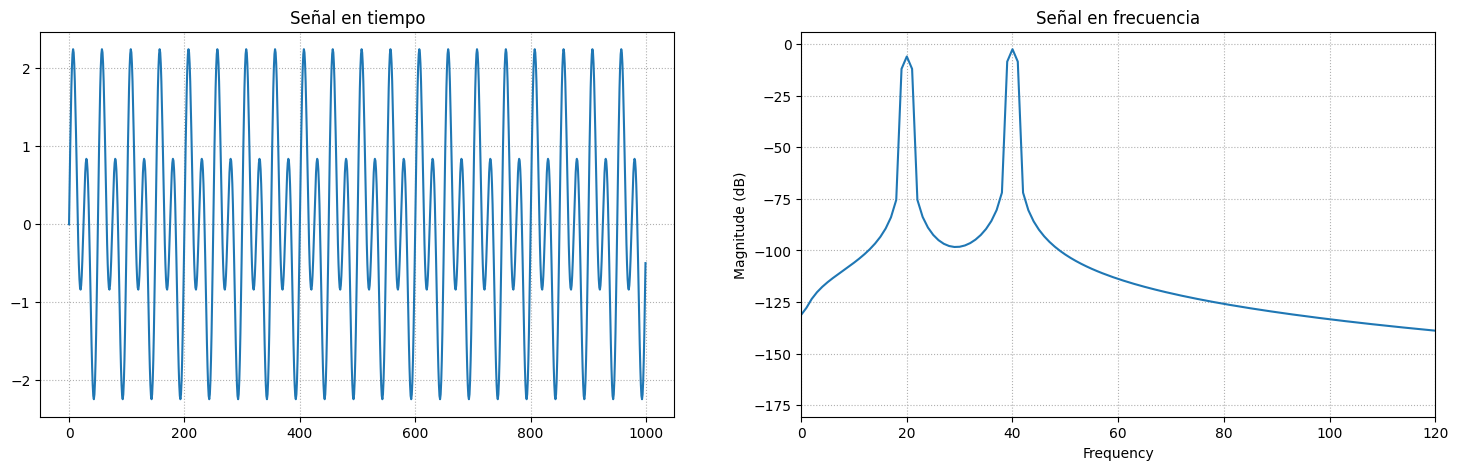

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plt.figure(figsize=(18,5))

plt.subplot(1,2,1)
plt.title("Señal en tiempo")
plt.plot(ui.signals[0])
plt.grid(ls=":")

plt.subplot(1,2,2)
plt.title("Señal en frecuencia")
plt.magnitude_spectrum(ui.signals[0], Fs=1000, scale='dB')
plt.grid(ls=":")
plt.xlim(0,120)

plt.show()

## Creación de filtros

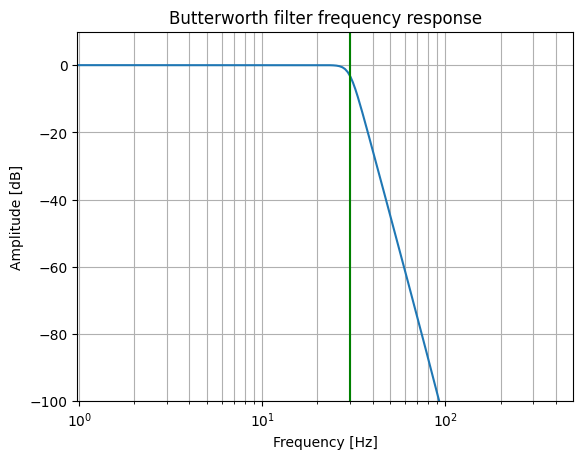

In [ ]:
from scipy.signal import butter, freqz

#b, a = butter(8, 30, 'low', 1000)
b, a = butter(10, 30, btype='low', fs=ui.fs[0])

w, h = freqz(b, a, fs = ui.fs[0])

plt.semilogx(w, 20 * np.log10(abs(h)))
plt.title('Butterworth filter frequency response')
plt.xlabel('Frequency [Hz]')
plt.ylabel('Amplitude [dB]')
plt.margins(0, 0.1)
plt.grid(which='both', axis='both')
plt.ylim(-100, 10)
plt.axvline(30, color='green') # cutoff frequency
plt.show()

## Evaluación del filtro

In [ ]:
from scipy.signal import dlti,dimpulse, dstep, dfreqresp

system = dlti(b, a, dt=1/ui.fs[0])

print(system)

TransferFunctionDiscrete(
array([3.11484549e-11, 3.11484549e-10, 1.40168047e-09, 3.73781459e-09,
       6.54117554e-09, 7.84941064e-09, 6.54117554e-09, 3.73781459e-09,
       1.40168047e-09, 3.11484549e-10, 3.11484549e-11]),
array([   1.        ,   -8.79517035,   34.87498282,  -82.09589685,
        127.04294386, -135.03554288,   99.83507904,  -50.69181843,
         16.91672279,   -3.35030545,    0.29900548]),
dt: 0.001
)


### Respuesta al impulso

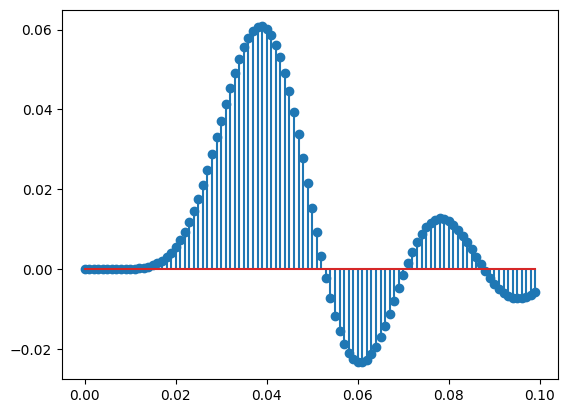

In [ ]:
t, y = dimpulse(system)

plt.stem(t, y[0])
plt.show()

### Respuesta al escalón

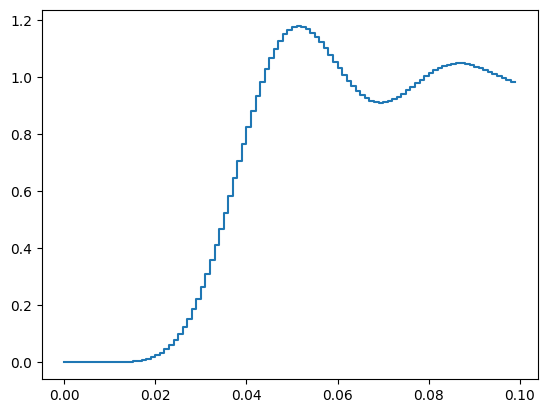

In [ ]:
t, y = dstep(system)

plt.step(t, y[0])
plt.show()

### Respuesta en frecuencia

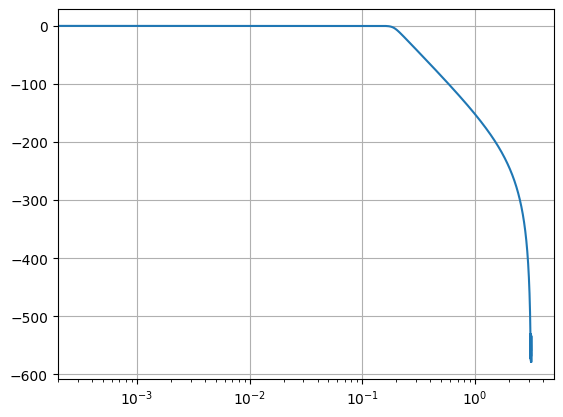

In [ ]:
w, h = dfreqresp(system)

plt.semilogx(w, 20*np.log10(abs(h)))
plt.grid()
plt.show()

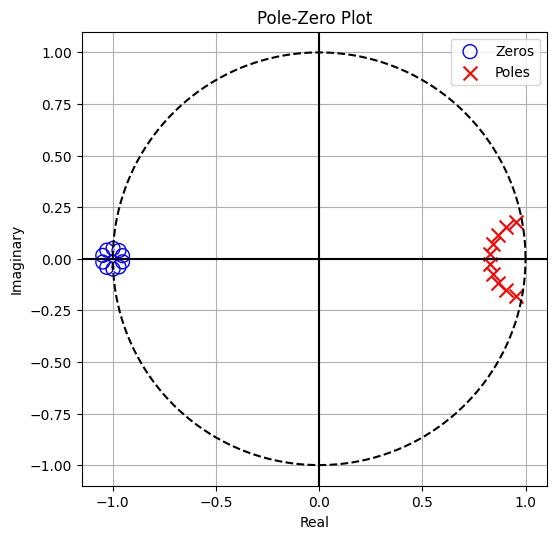

In [ ]:
from scipy.signal import tf2zpk


# Conversión a ZPK, una solo linea de código
#z, p, k = tf2zpk(b, a)

# o convertir a ZPK para  obtener polos, ceros y ganancia, mas lineas de código
zpk = system.to_zpk()
z = zpk.zeros
p = zpk.poles
k = zpk.gain

# =========================
# Gráfico polo-cero
# =========================

fig, ax = plt.subplots(figsize=(6,6))

# círculo unitario
theta = np.linspace(0, 2*np.pi, 500)
ax.plot(np.cos(theta), np.sin(theta), 'k--')

# zeros
ax.scatter(np.real(z), np.imag(z),
           marker='o', facecolors='none',
           edgecolors='b', s=100, label='Zeros')

# poles
ax.scatter(np.real(p), np.imag(p),
           marker='x',
           color='r', s=100, label='Poles')

ax.axhline(0, color='black')
ax.axvline(0, color='black')

ax.set_xlabel('Real')
ax.set_ylabel('Imaginary')
ax.set_title('Pole-Zero Plot')
ax.grid(True)
ax.legend()

ax.set_aspect('equal')

plt.show()

## Aplicación del filtro

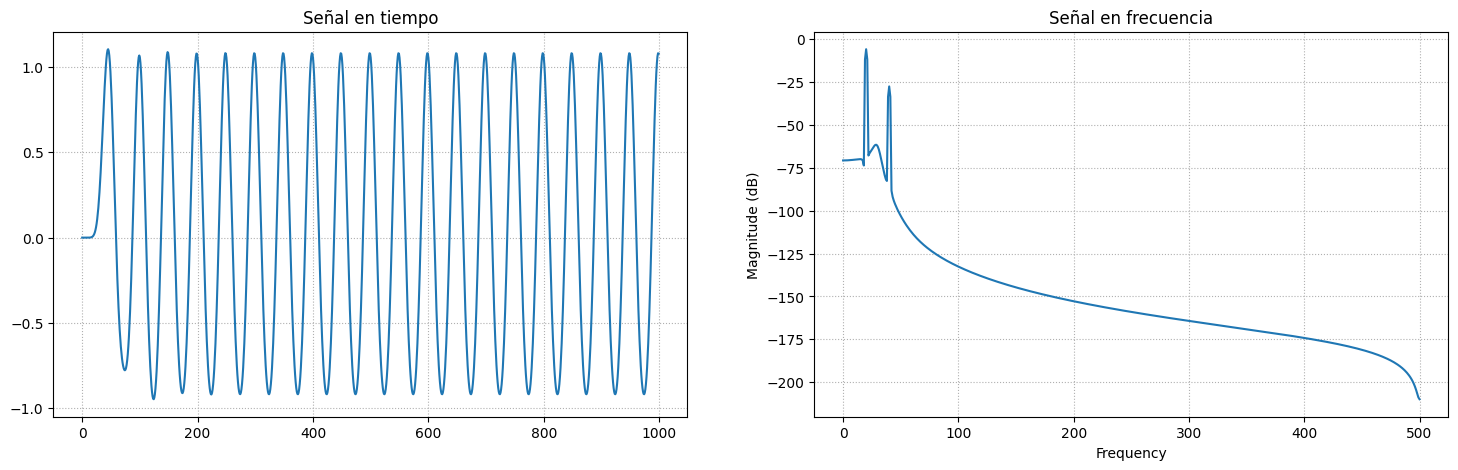

In [ ]:
from scipy.signal import lfilter

y = lfilter(b, a, ui.signals[0])

plt.figure(figsize=(18,5))

plt.subplot(1,2,1)
plt.title("Señal en tiempo")
plt.plot(y)
plt.grid(ls=":")

plt.subplot(1,2,2)
plt.title("Señal en frecuencia")
plt.magnitude_spectrum(y, Fs=1000, scale='dB')
plt.grid(ls=":")
#plt.xlim(0,120)

plt.show()